In [5]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import time
import math

plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

def fisher_comb(p1, p2):
    if p1 == 0 or p2 == 0: 
        return 0.0
    stat = -2 * (np.log(p1) + np.log(p2))
    return 1 - stats.chi2.cdf(stat, df=4)

def run_simulation_10000(n_sim=10000):
    rng = np.random.default_rng(1128)
    placebo_mean = 1.31
    n_stage1, n_stage2 = 120, 285
    rho = 0.6
    cov = [[1, rho], [rho, 1]]
    alpha_adj = 0.0125
    
    res = {
        'H0': {'naive': 0, 'bonf': 0, 'fisher': 0},
        'H1': {'naive': 0, 'bonf': 0, 'fisher': 0}
    }
    
    start_time = time.time()
    print(f"运行 {n_sim} 次模拟，请等待...")
    
    for i in range(n_sim):
        if (i + 1) % 2000 == 0:
            print(f"  进度: {(i+1)} / {n_sim} ...")
            
        for scen, effects in [('H0', [0,0,0,0]), ('H1', [0.05, 0.08, 0.11, 0.14])]:
            s1_doses = [rng.multivariate_normal([placebo_mean + eff]*2, cov, n_stage1) for eff in effects]
            s1_pbo = rng.multivariate_normal([placebo_mean]*2, cov, n_stage1)
            
            means = [d[:, 0].mean() for d in s1_doses]
            selected_idx = np.argsort(means)[-2:]
            
            s2_doses = [rng.multivariate_normal([placebo_mean + effects[idx]]*2, cov, n_stage2) for idx in selected_idx]
            s2_pbo = rng.multivariate_normal([placebo_mean]*2, cov, n_stage2)
            
            comb_pbo_t = np.concatenate([s1_pbo[:, 0], s2_pbo[:, 0]])
            comb_pbo_a = np.concatenate([s1_pbo[:, 1], s2_pbo[:, 1]])
            
            n_flag = b_flag = f_flag = False
            
            for k, idx in enumerate(selected_idx):
                comb_t = np.concatenate([s1_doses[idx][:, 0], s2_doses[k][:, 0]])
                comb_a = np.concatenate([s1_doses[idx][:, 1], s2_doses[k][:, 1]])
                
                _, pt = stats.ttest_ind(comb_t, comb_pbo_t, equal_var=False, alternative='greater')
                _, pa = stats.ttest_ind(comb_a, comb_pbo_a, equal_var=False, alternative='greater')
                
                _, p1_t = stats.ttest_ind(s1_doses[idx][:, 0], s1_pbo[:, 0], equal_var=False, alternative='greater')
                _, p1_a = stats.ttest_ind(s1_doses[idx][:, 1], s1_pbo[:, 1], equal_var=False, alternative='greater')
                _, p2_t = stats.ttest_ind(s2_doses[k][:, 0], s2_pbo[:, 0], equal_var=False, alternative='greater')
                _, p2_a = stats.ttest_ind(s2_doses[k][:, 1], s2_pbo[:, 1], equal_var=False, alternative='greater')
                
                if pt < 0.05 or pa < 0.05: n_flag = True
                if pt < alpha_adj or pa < alpha_adj: b_flag = True
                if fisher_comb(p1_t, p2_t) < alpha_adj or fisher_comb(p1_a, p2_a) < alpha_adj: f_flag = True
                    
            if n_flag: res[scen]['naive'] += 1
            if b_flag: res[scen]['bonf'] += 1
            if f_flag: res[scen]['fisher'] += 1

    fwers = [res['H0']['naive']/n_sim, res['H0']['bonf']/n_sim, res['H0']['fisher']/n_sim]
    powers = [res['H1']['naive']/n_sim, res['H1']['bonf']/n_sim, res['H1']['fisher']/n_sim]
    
    def get_ci(p, n):
        se = math.sqrt(p * (1 - p) / n)
        return p, (p - 1.96*se, p + 1.96*se)

    cis = [get_ci(f, n_sim) for f in fwers]
    
    print(f"\n模拟完成！总耗时: {time.time() - start_time:.1f} 秒")
    print("\n" + "="*60)
    print("=== 最终数值结果 (N=10,000) ===")
    print(f"FWER Naive:  {fwers[0]*100:.2f}% (95% CI: {cis[0][1][0]*100:.2f}%-{cis[0][1][1]*100:.2f}%)")
    print(f"FWER Bonf:   {fwers[1]*100:.2f}% (95% CI: {cis[1][1][0]*100:.2f}%-{cis[1][1][1]*100:.2f}%)")
    print(f"FWER Fisher: {fwers[2]*100:.2f}% (95% CI: {cis[2][1][0]*100:.2f}%-{cis[2][1][1]*100:.2f}%)")
    print("-" * 60)
    print(f"Power Naive:  {powers[0]*100:.2f}%")
    print(f"Power Bonf:   {powers[1]*100:.2f}%")
    print(f"Power Fisher: {powers[2]*100:.2f}%")
    print("="*60 + "\n")
    
    return fwers, powers

In [6]:
fwers, powers = run_simulation_10000(10000)

运行 10000 次模拟，请等待...
  进度: 2000 / 10000 ...
  进度: 4000 / 10000 ...
  进度: 6000 / 10000 ...
  进度: 8000 / 10000 ...
  进度: 10000 / 10000 ...

模拟完成！总耗时: 135.9 秒

=== 最终数值结果 (N=10,000) ===
FWER Naive:  18.90% (95% CI: 18.13%-19.67%)
FWER Bonf:   5.51% (95% CI: 5.06%-5.96%)
FWER Fisher: 5.92% (95% CI: 5.46%-6.38%)
------------------------------------------------------------
Power Naive:  83.59%
Power Bonf:   60.91%
Power Fisher: 57.98%



图像已成功保存至 outputs/figures/final_fwer_and_power.png


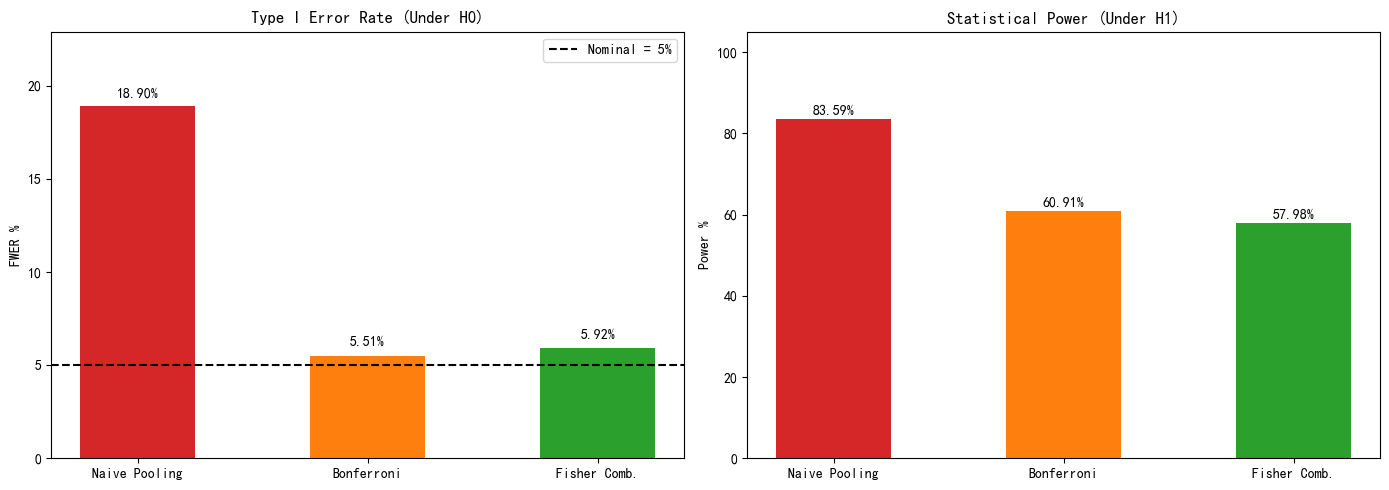

In [7]:
import os
os.makedirs('outputs/figures', exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = ['Naive Pooling', 'Bonferroni', 'Fisher Comb.']
colors = ['#d62728', '#ff7f0e', '#2ca02c']

fwers_pct = [f * 100 for f in fwers]
axes[0].bar(labels, fwers_pct, color=colors, width=0.5)
axes[0].axhline(5, color='black', linestyle='--', label='Nominal = 5%')
axes[0].set_title('Type I Error Rate (Under H0)', fontsize=12)
axes[0].set_ylabel('FWER %')
axes[0].legend()
axes[0].set_ylim(0, max(fwers_pct) + 4)
for i, v in enumerate(fwers_pct):
    axes[0].text(i, v + 0.5, f"{v:.2f}%", ha='center', fontweight='bold')

powers_pct = [p * 100 for p in powers]
axes[1].bar(labels, powers_pct, color=colors, width=0.5)
axes[1].set_title('Statistical Power (Under H1)', fontsize=12)
axes[1].set_ylabel('Power %')
axes[1].set_ylim(0, 105)
for i, v in enumerate(powers_pct):
    axes[1].text(i, v + 1, f"{v:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('outputs/figures/final_fwer_and_power.png', dpi=150)
print("图像已成功保存至 outputs/figures/final_fwer_and_power.png")
plt.show()